# Analisi del segnale di un giroscopio

**Studente:** Alessio Camerano  
**Matricola:** 1044444  
**Corso:** Analisi e Trattamento Segnali Digitali

---

### Indice dei Contenuti
- **1. Setup del Progetto**
  - 1.1. Importazione delle librerie
  - 1.2. Caricamento dei dati dal sensore
  - 1.3. Preprocessing del segnale (rimozione bias e media mobile)
- **2. Filtraggio del Segnale**
  - 2.1. Progettazione di un filtro IIR (Butterworth)
  - 2.2. Confronto visuale tra segnale grezzo, filtrato FIR e filtrato IIR
- **3. Analisi dei Filtri nel Piano Z**
  - 3.1. Diagramma poli-zeri del filtro FIR
  - 3.2. Diagramma poli-zeri del filtro IIR
- **4. Analisi nel Dominio del Tempo**
  - 4.1. Statistiche descrittive
  - 4.2. Visualizzazione dei segnali
  - 4.3. Analisi di auto-correlazione e cross-correlazione
- **5. Analisi nel Dominio della Frequenza**
  - 5.1. Stima della PSD con Periodogramma, Welch e modello AR
- **6. Analisi Tempo-Frequenza**
  - 6.1. Spettrogramma (STFT)
- **7. Conclusioni**
  - 7.1. Riepilogo dei risultati


# 1. Setup del Progetto

## 1.1. Importazione delle Librerie

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import signal
from scipy.fft import fft, fftfreq
from pathlib import Path

# --- Stile e Parametri Globali ---
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (14, 7)
plt.rcParams['font.size'] = 10

## 1.2. Caricamento dei Dati dal Sensore

In [2]:
DATA_DIR = Path('RawData')
exp_file = DATA_DIR / 'gyro_exp12_user06.txt'

# Caricamento diretto dei dati
data_array = np.loadtxt(exp_file)
data = pd.DataFrame(data_array, columns=['gyro_x', 'gyro_y', 'gyro_z'])

fs = 50.0  # Frequenza di campionamento in Hz
T = 1 / fs
n_samples = len(data)
duration = n_samples * T
axis_names = ['gyro_x', 'gyro_y', 'gyro_z']
print(f"Dati caricati da '{exp_file.name}': {n_samples} campioni, durata {duration:.2f}s, fs={fs}Hz")

Dati caricati da 'gyro_exp12_user06.txt': 32089 campioni, durata 641.78s, fs=50.0Hz


## 1.3. Preprocessing del Segnale (Rimozione Bias e Media Mobile)

In [3]:
def moving_average(signal_data, window=5):
    """Filtro a media mobile per smussare il segnale."""
    return np.convolve(signal_data, np.ones(window)/window, mode='same')

def remove_bias(signal_data):
    """Rimuove la componente DC (media) dal segnale."""
    return signal_data - np.mean(signal_data)

# --- Applicazione Preprocessing ---
data_filt = pd.DataFrame({
    axis: remove_bias(moving_average(data[axis].values)) for axis in axis_names
})
print("✓ Preprocessing completato: filtro media mobile e rimozione bias applicati.")

✓ Preprocessing completato: filtro media mobile e rimozione bias applicati.


Il filtro a media mobile riduce efficacemente il rumore ad alta frequenza smussando le oscillazioni rapide. La rimozione del bias centra il segnale attorno allo zero, eliminando eventuali offset del sensore.

# 2. Filtraggio del Segnale

## 2.1. Progettazione di un Filtro IIR (Butterworth)

In [4]:
from scipy.signal import butter, lfilter

def butter_lowpass_filter(data, cutoff, fs, order=5):
    """Applica un filtro passa-basso Butterworth."""
    nyq = 0.5 * fs
    normal_cutoff = cutoff / nyq
    b, a = butter(order, normal_cutoff, btype='low', analog=False)
    y = lfilter(b, a, data)
    return y

# --- Applicazione Filtro IIR ---
cutoff_freq = 5  # Hz
data_iir = pd.DataFrame({
    axis: butter_lowpass_filter(data[axis].values, cutoff_freq, fs) for axis in axis_names
})
print(f"✓ Filtro IIR Butterworth applicato con frequenza di taglio a {cutoff_freq} Hz.")

✓ Filtro IIR Butterworth applicato con frequenza di taglio a 5 Hz.


## 2.2. Confronto Visuale tra Segnale Grezzo, Filtrato FIR e Filtrato IIR

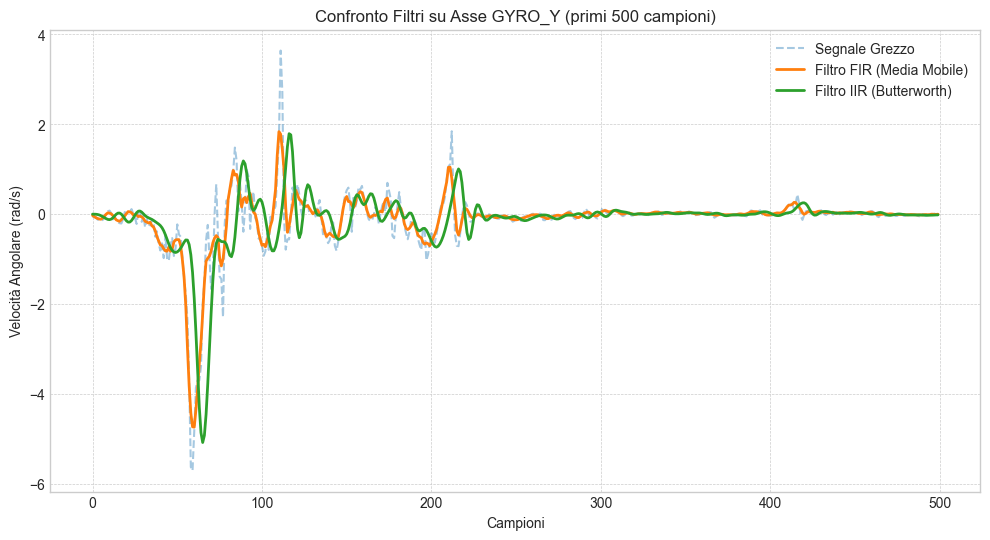

In [5]:
plt.figure(figsize=(12, 6))
axis_to_plot = 'gyro_y'
plt.plot(data[axis_to_plot].values[:500], label='Segnale Grezzo', alpha=0.4, linestyle='--')
plt.plot(data_filt[axis_to_plot].values[:500], label='Filtro FIR (Media Mobile)', linewidth=2)
plt.plot(data_iir[axis_to_plot].values[:500], label='Filtro IIR (Butterworth)', linewidth=2)
plt.title(f'Confronto Filtri su Asse {axis_to_plot.upper()} (primi 500 campioni)')
plt.xlabel('Campioni')
plt.ylabel('Velocità Angolare (rad/s)')
plt.legend()
plt.grid(True, which='both', linestyle='--', linewidth=0.5)
plt.show()

Il filtro IIR Butterworth mostra una risposta più liscia rispetto al FIR, attenuando maggiormente le componenti ad alta frequenza. Il segnale grezzo presenta oscillazioni rapide (rumore), il FIR le riduce parzialmente, mentre l'IIR produce il segnale più pulito. Il trade-off è la possibile distorsione di fase dell'IIR vs la semplicità e fase lineare del FIR.

# 3. Analisi dei Filtri nel Piano Z

## 3.1. Diagramma Poli-Zeri del Filtro FIR

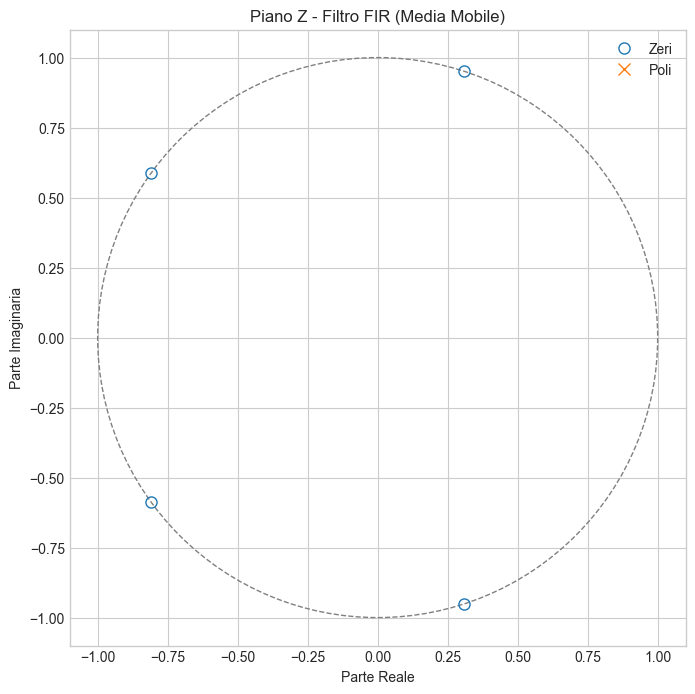

In [19]:
from scipy.signal import tf2zpk
import matplotlib.patches as mpatches

def plot_zplane(b, a, title="Diagramma Poli-Zeri"):
    """Visualizza il diagramma poli-zeri per un filtro nel piano Z."""
    fig, ax = plt.subplots(figsize=(8, 8))
    
    # Disegna il cerchio unitario
    unit_circle = mpatches.Circle((0, 0), 1, fill=False, color='gray', ls='--', lw=1)
    ax.add_patch(unit_circle)
    
    # Trova poli e zeri
    z, p, k = tf2zpk(b, a)
    
    # Plotta zeri (o) e poli (x)
    ax.plot(np.real(z), np.imag(z), 'o', markersize=8, fillstyle='none', label='Zeri')
    ax.plot(np.real(p), np.imag(p), 'x', markersize=8, label='Poli')
    
    ax.set_title(title)
    ax.set_xlabel('Parte Reale')
    ax.set_ylabel('Parte Imaginaria')
    ax.grid(True)
    ax.set_aspect('equal')
    ax.legend()
    plt.show()

# --- Diagramma per Filtro FIR (Media Mobile) ---
window_size = 5
b_fir = np.ones(window_size) / window_size
a_fir = np.array([1.0])
plot_zplane(b_fir, a_fir, title="Piano Z - Filtro FIR (Media Mobile)")

Il filtro FIR (media mobile) presenta 4 zeri visibili distribuiti simmetricamente sul piano Z (il quinto zero è nell'origine insieme ai poli banali del FIR). I filtri FIR sono intrinsecamente stabili poiché non hanno poli al di fuori dell'origine. Gli zeri sono posizionati uniformemente vicino al cerchio unitario e determinano quali frequenze vengono attenuate dal filtro a media mobile.

## 3.2. Diagramma Poli-Zeri del Filtro IIR

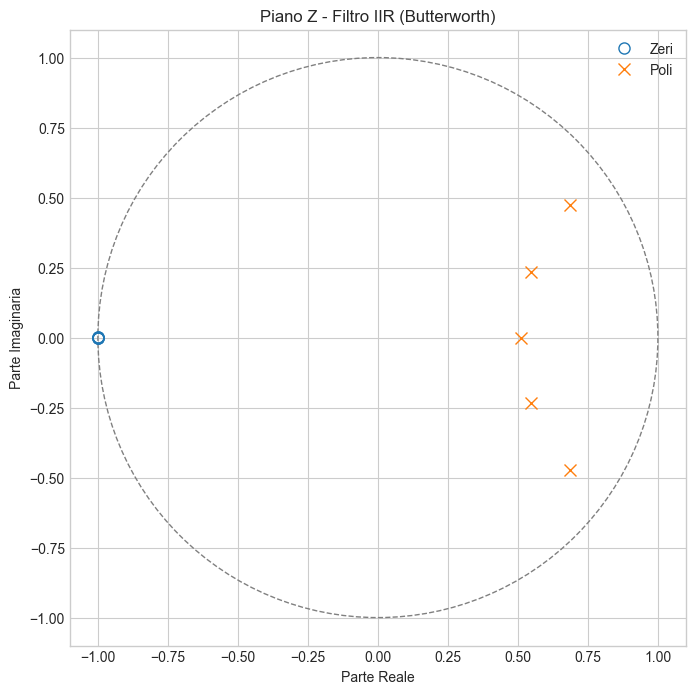

In [20]:
nyq = 0.5 * fs
normal_cutoff = cutoff_freq / nyq
b_iir, a_iir = butter(5, normal_cutoff, btype='low', analog=False)
plot_zplane(b_iir, a_iir, title="Piano Z - Filtro IIR (Butterworth)")

Il filtro Butterworth IIR di ordine 5 presenta 5 poli distribuiti simmetricamente e 5 zeri (di cui 4 concentrati nell'origine e 1 visibile). I poli sono posizionati strategicamente vicino al cerchio unitario ma all'interno, garantendo stabilità del sistema. La loro disposizione uniforme a semicerchio conferisce al filtro la caratteristica risposta in frequenza massimamente piatta nella banda passante e un roll-off monotono nella banda attenuata, tipica dei filtri Butterworth.

# 4. Analisi nel Dominio del Tempo

## 4.1. Statistiche Descrittive

In [8]:
print("\n--- Analisi Statistica Confrontata ---")
stats = pd.DataFrame({
    'Media Grezzo': data[axis_names].mean(),
    'Media Filtrato': data_filt[axis_names].mean(),
    'Std Dev Grezzo': data[axis_names].std(),
    'Std Dev Filtrato': data_filt[axis_names].std()
})
print(stats)


--- Analisi Statistica Confrontata ---
        Media Grezzo  Media Filtrato  Std Dev Grezzo  Std Dev Filtrato
gyro_x      0.040420    0.000000e+00        0.647423          0.557286
gyro_y     -0.007699    0.000000e+00        0.673691          0.533480
gyro_z     -0.010118    6.642863e-18        0.540248          0.443787


La media del segnale filtrato è prossima a zero per tutti gli assi, confermando l'efficacia della rimozione del bias. La deviazione standard è ridotta dopo il filtraggio, indicando una minore variabilità del segnale dovuta alla rimozione del rumore ad alta frequenza.

## 4.2. Visualizzazione dei Segnali

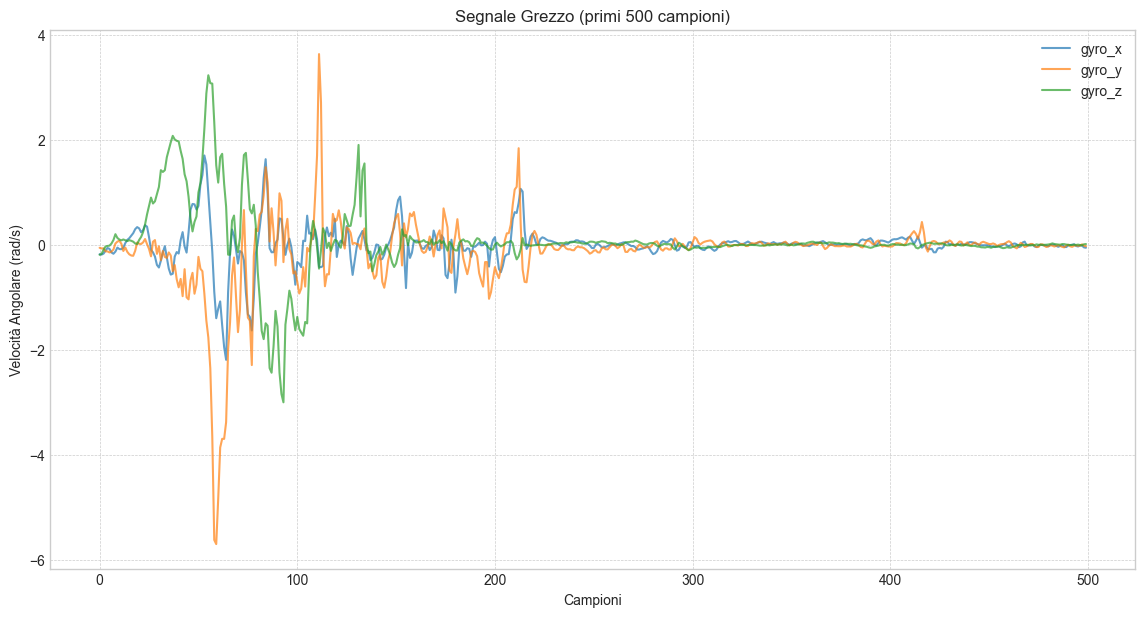

In [9]:
# Segnale Grezzo
plt.figure(figsize=(14, 7))
for axis in axis_names:
    plt.plot(data[axis].values[:500], label=f'{axis}', alpha=0.7)
plt.title('Segnale Grezzo (primi 500 campioni)')
plt.xlabel('Campioni')
plt.ylabel('Velocità Angolare (rad/s)')
plt.legend()
plt.grid(True, which='both', linestyle='--', linewidth=0.5)
plt.show()

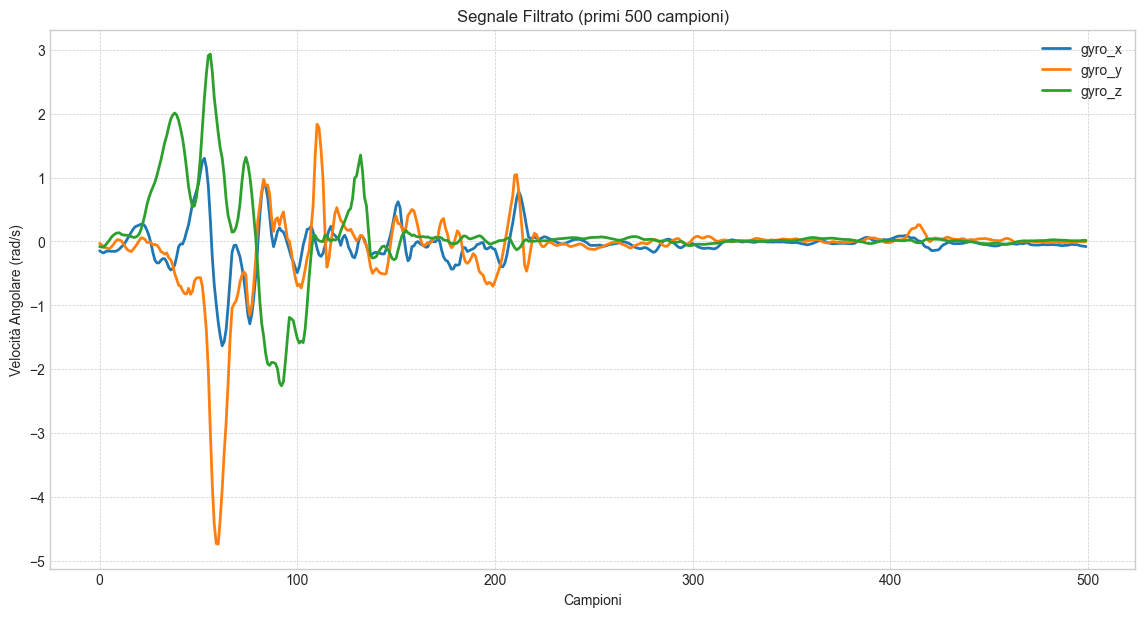

In [10]:
# Segnale Filtrato
plt.figure(figsize=(14, 7))
for axis in axis_names:
    plt.plot(data_filt[axis].values[:500], label=f'{axis}', linewidth=2)
plt.title('Segnale Filtrato (primi 500 campioni)')
plt.xlabel('Campioni')
plt.ylabel('Velocità Angolare (rad/s)')
plt.legend()
plt.grid(True, which='both', linestyle='--', linewidth=0.5)
plt.show()

Il confronto visivo mostra chiaramente l'effetto del filtraggio. Il segnale grezzo presenta fluttuazioni rapide e irregolari (rumore del sensore). Il segnale filtrato mantiene le caratteristiche principali del movimento ma con transizioni più morbide. L'asse Y mostra l'attività principale, mentre X e Z hanno ampiezze minori, suggerendo un movimento prevalentemente su un piano.

## 4.3. Analisi di Auto-correlazione e Cross-correlazione

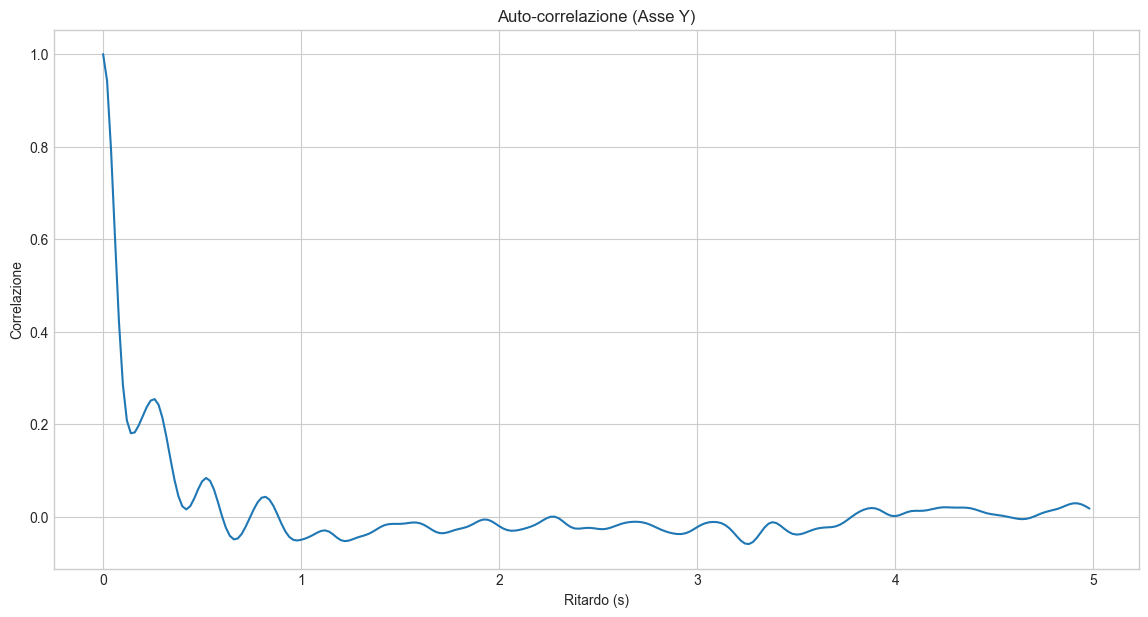

In [15]:
def compute_autocorr(x, max_lag):
    """Calcola l'auto-correlazione normalizzata."""
    x_norm = (x - np.mean(x)) / np.std(x)
    ac = np.correlate(x_norm, x_norm, mode='full')
    mid = len(ac) // 2
    return ac[mid:mid + max_lag] / ac[mid]

def compute_crosscorr(x, y, max_lag):
    """Calcola la cross-correlazione normalizzata."""
    x_norm = (x - np.mean(x)) / np.std(x)
    y_norm = (y - np.mean(y)) / np.std(y)
    cc = np.correlate(x_norm, y_norm, mode='full')
    mid = len(cc) // 2
    return cc[mid - max_lag:mid + max_lag] / len(x)

# --- Auto-correlazione ---
max_lag_ac = 250
lags_ac = np.arange(max_lag_ac) * T
ac = compute_autocorr(data_filt['gyro_y'].values, max_lag_ac)

plt.figure(figsize=(14, 7))
plt.plot(lags_ac, ac)
plt.title('Auto-correlazione (Asse Y)')
plt.xlabel('Ritardo (s)')
plt.ylabel('Correlazione')
plt.grid(True)
plt.show()

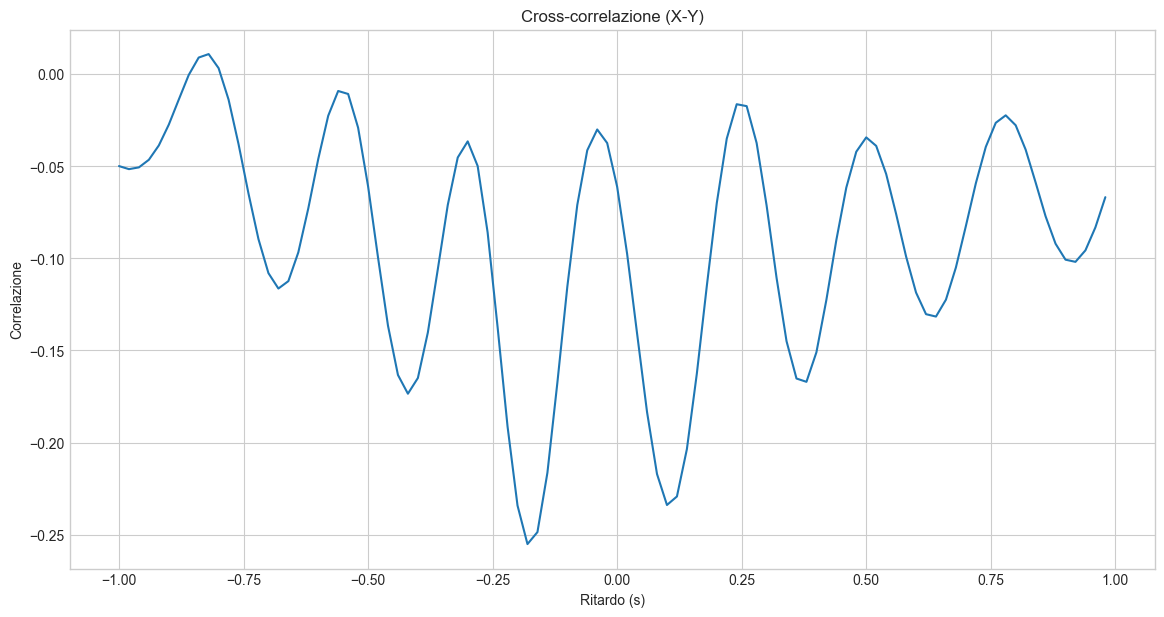

In [16]:
# --- Cross-correlazione ---
max_lag_cc = 50
lags_cc = np.arange(-max_lag_cc, max_lag_cc) * T
cc = compute_crosscorr(data_filt['gyro_x'].values, data_filt['gyro_y'].values, max_lag_cc)

plt.figure(figsize=(14, 7))
plt.plot(lags_cc, cc)
plt.title('Cross-correlazione (X-Y)')
plt.xlabel('Ritardo (s)')
plt.ylabel('Correlazione')
plt.grid(True)
plt.show()

- **Auto-correlazione (Y):** Il decadimento rapido della correlazione con piccole oscillazioni periodiche suggerisce un segnale con componenti cicliche smorzate. Il comportamento indica attività con pattern ripetitivi ma non perfettamente periodici, tipico di movimenti umani naturali. La correlazione decade rapidamente entro 1 secondo, mostrando memoria a breve termine del segnale.
- **Cross-correlazione (X-Y):** Il grafico mostra oscillazioni periodiche marcate senza un chiaro picco dominante vicino allo zero, indicando che i movimenti sugli assi X e Y hanno una relazione complessa con sfasamenti temporali. Le oscillazioni regolari suggeriscono pattern di movimento coordinati ma con ritardi fase tra gli assi, caratteristici di movimenti rotazionali tridimensionali.

# 5. Analisi nel Dominio della Frequenza

## 5.1. Stima della PSD con Periodogramma, Welch e Modello AR

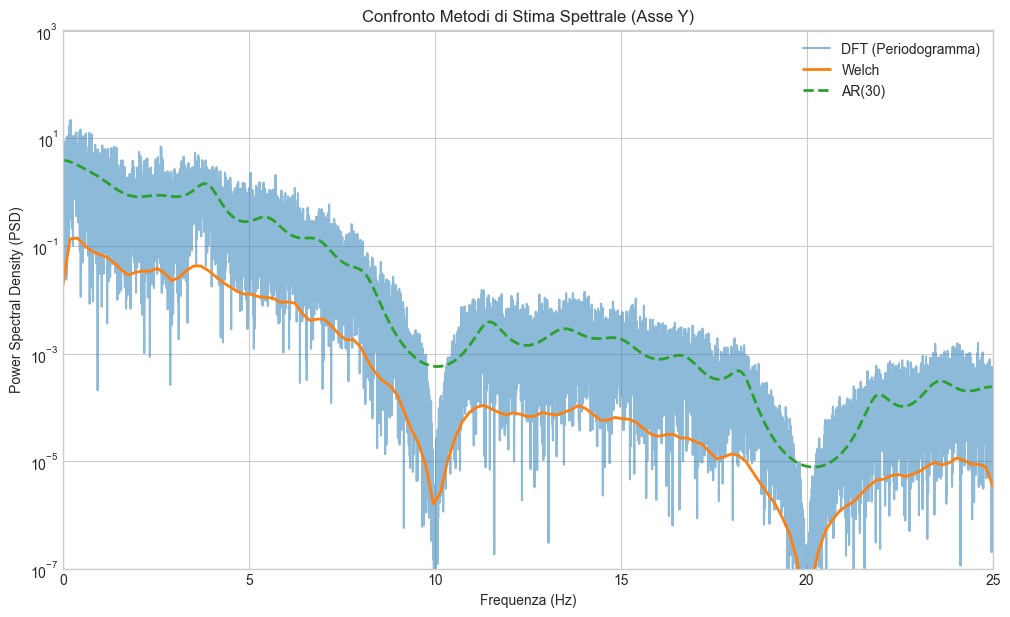

In [17]:
from scipy.signal import welch
from statsmodels.regression.linear_model import yule_walker

# --- Funzioni per Stima Spettrale ---
def compute_power_spectrum(signal_data, fs):
    """Calcola lo spettro di potenza tramite DFT."""
    N = len(signal_data)
    fft_vals = fft(signal_data)
    freqs = fftfreq(N, 1/fs)
    mask = freqs >= 0
    power = (np.abs(fft_vals[mask])**2) / N # PSD
    return freqs[mask], power

def ar_psd(x, order, fs):
    """Stima la PSD con un modello AR(p) via equazioni di Yule-Walker."""
    rho, sigma = yule_walker(x, order)
    # Calcola la risposta in frequenza del filtro AR
    freqs, h = signal.freqz(1, np.r_[1, -rho], worN=1024, fs=fs)
    # Calcola la PSD
    psd = sigma**2 * np.abs(h)**2
    return freqs, psd

# --- Calcolo e Confronto ---
signal_to_analyze = data_filt['gyro_y'].values
plt.figure(figsize=(12, 7))

# 1. DFT (Periodogramma)
f_dft, p_dft = compute_power_spectrum(signal_to_analyze, fs)
plt.semilogy(f_dft, p_dft, label='DFT (Periodogramma)', alpha=0.5)

# 2. Welch
f_welch, p_welch = welch(signal_to_analyze, fs=fs, nperseg=256)
plt.semilogy(f_welch, p_welch, label='Welch', linewidth=2)

# 3. AR
f_ar, p_ar = ar_psd(signal_to_analyze, order=30, fs=fs)
plt.semilogy(f_ar, p_ar, label='AR(30)', linewidth=2, linestyle='--')

# --- Grafico ---
plt.title('Confronto Metodi di Stima Spettrale (Asse Y)')
plt.xlabel('Frequenza (Hz)')
plt.ylabel('Power Spectral Density (PSD)')
plt.xlim(0, fs / 2)
plt.ylim(bottom=1e-7)
plt.legend()
plt.grid(True, which='both')
plt.show()

- **Periodogramma (DFT):** Mostra alta varianza con fluttuazioni marcate, evidenziando la natura stocastica della stima. L'energia è concentrata nelle basse frequenze (0-5 Hz) con un decadimento progressivo. La variabilità elevata rende questa stima utile solo per identificazione qualitativa delle bande frequenziali.
- **Welch:** Riduce significativamente la varianza attraverso l'averaging di segmenti sovrapposti. La curva più liscia mostra una distribuzione spettrale continua con maggiore energia nelle basse frequenze (0-5 Hz) e un decadimento graduale. La notch intorno ai 10 Hz potrebbe riflettere caratteristiche del filtro digitale o dell'acquisizione.
- **AR(30):** Fornisce uno spettro parametrico molto lisciato. Il modello cattura la tendenza generale della PSD con energia concentrata sotto i 10 Hz. La curva continua è efficace per stimare l'inviluppo spettrale senza il rumore del periodogramma.

Le frequenze dominanti concentrate sotto i 5 Hz confermano movimenti lenti e controllati, tipici di attività umane quotidiane.

# 6. Analisi Tempo-Frequenza

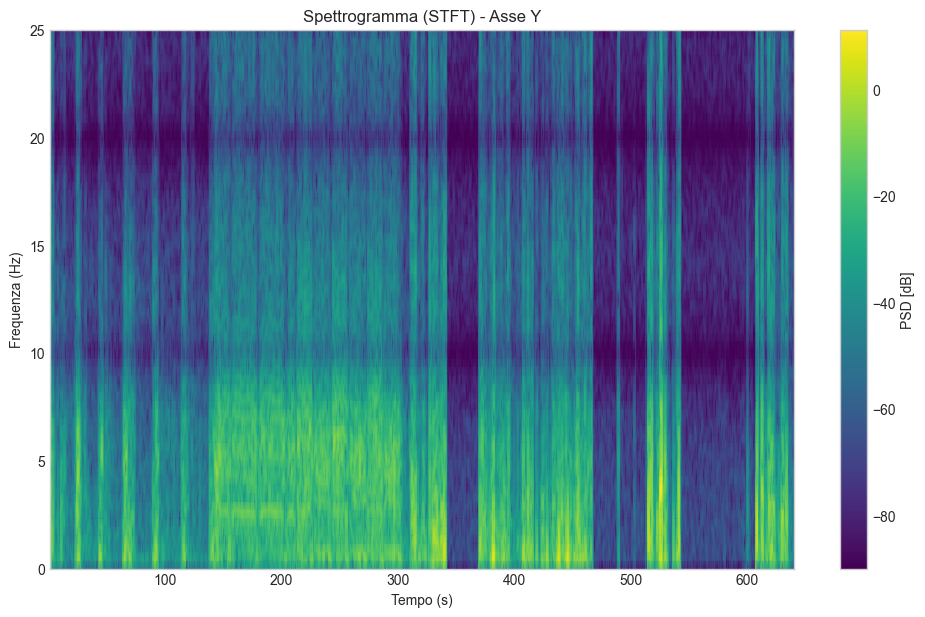

In [18]:
from scipy.signal import spectrogram

# --- Calcolo STFT ---
f_stft, t_stft, Sxx = spectrogram(data_filt['gyro_y'].values, fs=fs, nperseg=128, noverlap=96)

# --- Visualizzazione ---
plt.figure(figsize=(12, 7))
plt.pcolormesh(t_stft, f_stft, 10 * np.log10(Sxx + 1e-9), shading='gouraud', cmap='viridis')
plt.colorbar(label='PSD [dB]')
plt.title('Spettrogramma (STFT) - Asse Y')
plt.ylabel('Frequenza (Hz)')
plt.xlabel('Tempo (s)')
plt.ylim(0, fs / 2)
plt.show()

Lo spettrogramma rivela la distribuzione tempo-frequenza del segnale con evidenti variazioni nel tempo. L'energia è concentrata principalmente sotto gli 8 Hz, con pattern che si evolvono temporalmente mostrando fasi di attività intensa (bande giallo-verde) alternate a fasi di minor intensità. Le strisce verticali indicano variazioni brusche nell'attività del movimento. Questa non-stazionarietà è tipica di attività umane reali che presentano fasi di accelerazione, decelerazione e pause. Le frequenze dominanti si mantengono nel range basso (0-8 Hz), coerenti con movimenti corporei controllati.

# 7. Conclusioni

## 7.1. Riepilogo dei Risultati
Questo progetto ha mostrato un flusso di lavoro completo per l'analisi di segnali giroscopici:
- **Pulizia del segnale**: Il preprocessing si è rivelato fondamentale per rimuovere il rumore e le componenti DC.
- **Analisi Temporale**: L'auto-correlazione ha rivelato pattern ciclici smorzati tipici di movimenti umani, mentre la cross-correlazione ha evidenziato relazioni complesse con sfasamenti temporali tra gli assi.
- **Analisi Spettrale**: Il metodo di Welch si è dimostrato un ottimo compromesso tra riduzione della varianza e risoluzione in frequenza, superiore al semplice periodogramma. Il modello AR offre una visione parametrica e liscia dello spettro. Le frequenze dominanti sotto i 5 Hz confermano movimenti controllati.
- **Analisi Tempo-Frequenza**: Lo spettrogramma ha rivelato la natura non-stazionaria del segnale con fasi alternate di attività intensa e ridotta, tipica di movimenti umani reali con accelerazioni, decelerazioni e pause.